# 03 Model comparison (training set only)

Steps 3-6 of the project workflow: build leakage-free pipelines, cross-validate every candidate on the same grouped folds, select one winner. The test set is not loaded in this notebook.

## Decisions fixed before looking at any results

**Application.** A Vinho Verde producer pre-screens white wine batches before paying for an expert tasting panel. Positive = good wine (quality 7 or above).
- False positive: a mediocre batch is sent to the panel, wasting one tasting ($c_{FP} = 1$).
- False negative: a good batch is never tasted and is sold at the standard price, losing the premium margin ($c_{FN}$).

**Why $c_{FN} = 3$.**

> **TODO (group):** add the group's reasoning for $c_{FN}/c_{FP} = 3$ here, e.g. the cost of one expert tasting compared with the premium margin lost on one good batch, with a source for any figure quoted. No figures or sources have been filled in on your behalf.

Whatever the justification, `04_cost_threshold.ipynb` re-runs the analysis for $c_{FN}/c_{FP} \in \{1/3, 1/2, 1, 2, 3, 5, 10\}$ and reports the range of ratios over which the model beats both no-model policies, which shows how much the conclusions depend on this value.

**Duplicates and folds.** The training set has 3,168 unique wines and 3,926 rows: 758 rows are repeat measurements of a wine (exact copies on all 11 predictors and quality). Copies of one wine must not be split between a training and a validation fold, so we use `StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=211)` with `groups = wine_id`, the same folds for every candidate. All metrics are computed over rows, consistent with the test set, which also keeps its duplicates.

**CV metric for selection: PR-AUC (average precision).** About 21% of wines are good. PR-AUC measures how well a model ranks the rare good wines at the top, and unlike ROC-AUC it is not flattered by the many easy negatives. The no-skill baseline is the share of good wines, about 0.21. ROC-AUC, sensitivity, specificity and confusion matrices are reported for every model as supporting evidence.

**Thresholds in the comparison table.** The default 0.5, and the theoretical cost-optimal threshold $t^* = c_{FP}/(c_{FP}+c_{FN}) = 0.25$ for the base case (Lesson 5, Section 7.2). Neither is tuned here. The operating point is chosen in notebook 04.

**Candidates** (the three required by the brief), all on the same 11 log-transformed predictors (`wine_utils.transform`), with standardisation inside each pipeline so every fold learns its own means and SDs:
1. Logistic regression, unpenalised
2. LDA
3. Gaussian Naive Bayes

**Selection rule.**
1. Find the candidate with the highest mean CV PR-AUC.
2. One-SE rule: keep every candidate whose mean PR-AUC is within one SE of that best mean ($SE = SD_{folds}/\sqrt{10}$).
3. Among those, choose the one with the **lowest mean CV expected cost per wine at $t^* = 0.25$**.

The rule therefore uses both predictive performance (PR-AUC) and the FP/FN costs of the application, as the brief requires. (The earlier tie-break on the number of model terms no longer applies, because every candidate now uses the same 11 predictors.)

In [1]:
import json, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone
from sklearn.metrics import (average_precision_score, roc_auc_score, roc_curve,
                             precision_recall_curve, confusion_matrix)

from wine_utils import load_train, make_cv, candidate_models, expected_cost, C_FP, C_FN_BASE

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110
os.makedirs('results', exist_ok=True)

X, y, groups = load_train()
cv = make_cv(10)
splits = list(cv.split(X, y, groups))
T_STAR = C_FP / (C_FP + C_FN_BASE)
print(X.shape, '| unique wines =', groups.nunique(), '| share good =', y.mean().round(3), '| t* =', T_STAR)

(3926, 11) | unique wines = 3168 | share good = 0.216 | t* = 0.25


## Check the grouped folds
Every copy of a wine must sit in one fold only, and each fold should keep roughly the overall share of good wines.

In [2]:
fold_info = []
for k, (tr, va) in enumerate(splits):
    assert not set(groups.iloc[tr]) & set(groups.iloc[va]), f'wine_id on both sides of fold {k}'
    fold_info.append({'fold': k, 'validation rows': len(va),
                      'validation wines': groups.iloc[va].nunique(),
                      'share good': y.iloc[va].mean()})
print('No wine_id appears in both the training and validation side of any fold.')
pd.DataFrame(fold_info).round(3).set_index('fold').T

No wine_id appears in both the training and validation side of any fold.


fold,0,1,2,3,4,5,6,7,8,9
validation rows,393.000,393.000,393.000,392.000,393.000,393.000,392.000,392.000,392.000,393.000
validation wines,316.000,316.000,317.000,316.000,318.000,317.000,317.000,317.000,317.000,317.000
share good,0.216,0.216,0.216,0.214,0.216,0.216,0.214,0.217,0.217,0.216


## Cross-validate every candidate on the same 10 folds

For each fold we fit a fresh copy of the pipeline on 9 folds and score the held-out fold. We store the out-of-fold probabilities for the ROC and PR plots and for the threshold analysis in notebook 04.

In [3]:
def fold_metrics(y_true, prob):
    out = {'PR-AUC': average_precision_score(y_true, prob),
           'ROC-AUC': roc_auc_score(y_true, prob)}
    for t in (0.5, T_STAR):
        tn, fp, fn, tp = confusion_matrix(y_true, prob >= t, labels=[0, 1]).ravel()
        out[f'Sensitivity @{t:g}'] = tp / (tp + fn)
        out[f'Specificity @{t:g}'] = tn / (tn + fp)
    out[f'Cost/wine @{T_STAR:g}'] = expected_cost(y_true, prob, T_STAR, C_FN_BASE)
    return out

rows = []
oof = pd.DataFrame({'y': y.values, 'fold': -1, 'wine_id': groups.values}, index=X.index)
names = list(candidate_models())

with warnings.catch_warnings():
    warnings.simplefilter('ignore', category=RuntimeWarning)
    for name, model in candidate_models().items():
        for k, (tr, va) in enumerate(splits):
            m = clone(model).fit(X.iloc[tr], y.iloc[tr])
            prob = m.predict_proba(X.iloc[va])[:, 1]
            oof.iloc[va, oof.columns.get_loc('fold')] = k
            oof.loc[X.index[va], name] = prob
            rows.append({'model': name, 'fold': k, **fold_metrics(y.iloc[va].values, prob)})

folds = pd.DataFrame(rows)
print('done:', folds['model'].nunique(), 'models x', folds['fold'].nunique(), 'folds')

done: 3 models x 10 folds


## Comparison table
Mean across the 10 folds ± SE (SD of the fold scores / $\sqrt{10}$).

In [4]:
metrics = [c for c in folds.columns if c not in ('model', 'fold')]
g = folds.groupby('model', sort=False)
mean, se = g[metrics].mean(), g[metrics].std() / np.sqrt(10)

table = mean.round(3).astype(str) + ' ± ' + se.round(3).astype(str)
table.T

model,Logistic,LDA,Gaussian NB
PR-AUC,0.526 ± 0.017,0.531 ± 0.016,0.511 ± 0.018
ROC-AUC,0.79 ± 0.013,0.786 ± 0.013,0.776 ± 0.013
Sensitivity @0.5,0.269 ± 0.012,0.309 ± 0.012,0.634 ± 0.026
Specificity @0.5,0.949 ± 0.004,0.941 ± 0.004,0.787 ± 0.01
Sensitivity @0.25,0.711 ± 0.026,0.706 ± 0.026,0.762 ± 0.023
Specificity @0.25,0.756 ± 0.011,0.755 ± 0.009,0.675 ± 0.012
Cost/wine @0.25,0.379 ± 0.018,0.382 ± 0.017,0.409 ± 0.016


## ROC and PR curves (pooled out-of-fold probabilities)

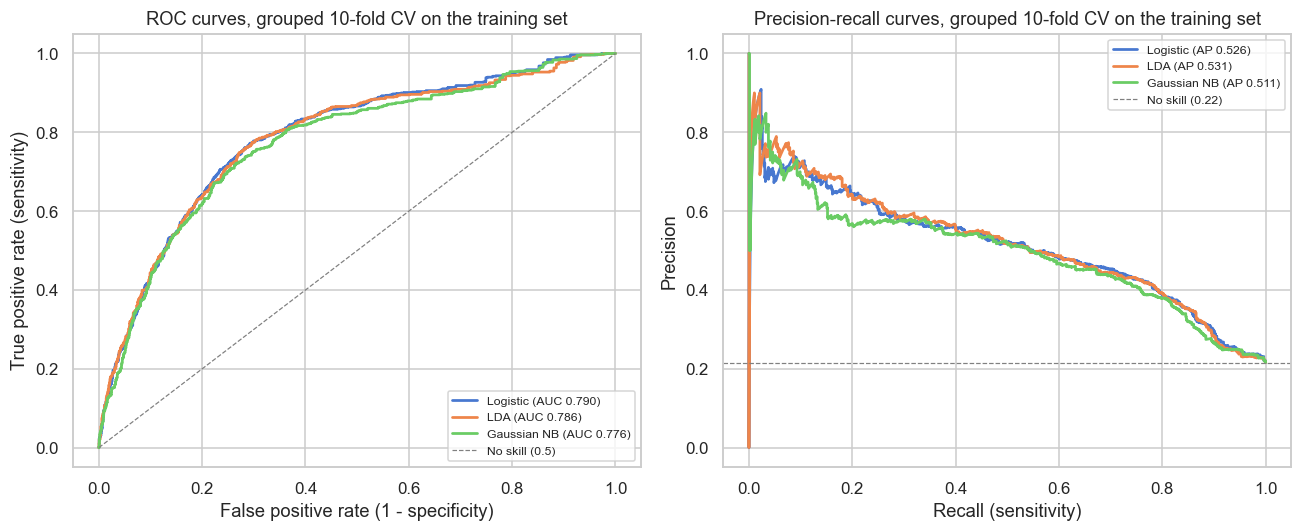

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for name in names:
    fpr, tpr, _ = roc_curve(oof['y'], oof[name])
    axes[0].plot(fpr, tpr, lw=1.8,
                 label=f"{name} (AUC {mean.loc[name, 'ROC-AUC']:.3f})")
    prec, rec, _ = precision_recall_curve(oof['y'], oof[name])
    axes[1].plot(rec, prec, lw=1.8,
                 label=f"{name} (AP {mean.loc[name, 'PR-AUC']:.3f})")

axes[0].plot([0, 1], [0, 1], color='grey', ls='--', lw=0.8, label='No skill (0.5)')
axes[0].set(xlabel='False positive rate (1 - specificity)',
            ylabel='True positive rate (sensitivity)',
            title='ROC curves, grouped 10-fold CV on the training set')
axes[1].axhline(y.mean(), color='grey', ls='--', lw=0.8,
                label=f'No skill ({y.mean():.2f})')
axes[1].set(xlabel='Recall (sensitivity)', ylabel='Precision',
            title='Precision-recall curves, grouped 10-fold CV on the training set')
for ax in axes:
    ax.legend(fontsize=8, loc='lower right' if ax is axes[0] else 'upper right')
plt.tight_layout()
plt.show()

## Confusion matrices (pooled out-of-fold predictions)
One per model, at the base-case cost threshold $t^* = 0.25$. Sensitivity and specificity at 0.5 are in the comparison table.

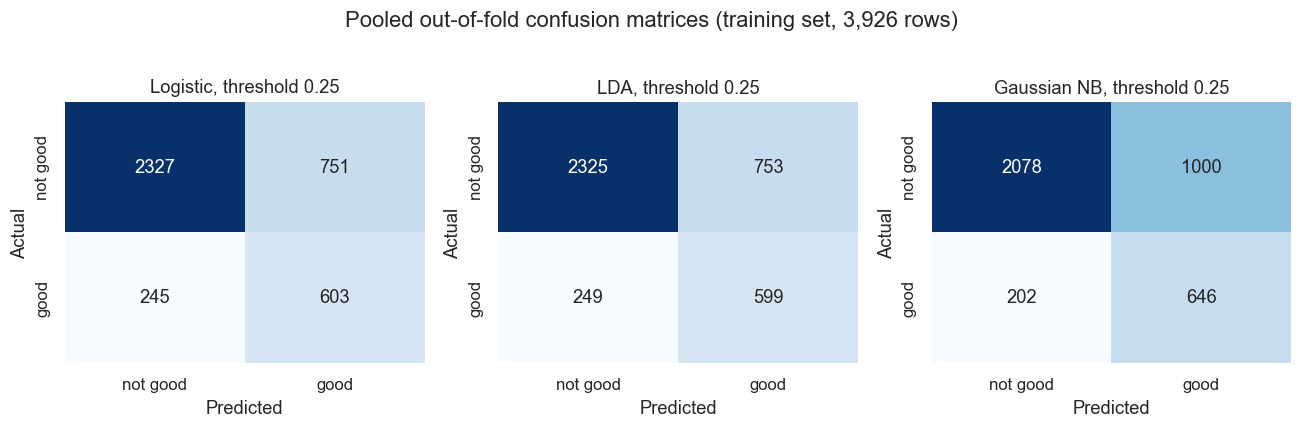

In [6]:
fig, axes = plt.subplots(1, len(names), figsize=(12, 3.8))
for ax, name in zip(axes, names):
    cm = confusion_matrix(oof['y'], oof[name] >= T_STAR)
    sns.heatmap(cm, annot=True, fmt='d', cbar=False, cmap='Blues', ax=ax,
                xticklabels=['not good', 'good'], yticklabels=['not good', 'good'])
    ax.set(title=f'{name}, threshold {T_STAR:g}', xlabel='Predicted', ylabel='Actual')
fig.suptitle('Pooled out-of-fold confusion matrices (training set, 3,926 rows)', y=1.02)
plt.tight_layout()
plt.show()

## Apply the selection rule

In [7]:
summary = pd.DataFrame({
    'PR-AUC mean': mean['PR-AUC'],
    'PR-AUC SE': se['PR-AUC'],
    'cost mean': mean[f'Cost/wine @{T_STAR:g}'],
    'cost SE': se[f'Cost/wine @{T_STAR:g}'],
})
top = summary['PR-AUC mean'].idxmax()
cutoff = summary.loc[top, 'PR-AUC mean'] - summary.loc[top, 'PR-AUC SE']
summary['within 1 SE of best'] = summary['PR-AUC mean'] >= cutoff

eligible = summary[summary['within 1 SE of best']].sort_values('cost mean')
winner = eligible.index[0]

print(f'Best mean PR-AUC: {top} ({summary.loc[top, "PR-AUC mean"]:.3f}); one-SE cut-off {cutoff:.3f}')
print('Eligible:', list(eligible.index))
print('Selected model (lowest cost at t* among eligible):', winner)
summary.round(4)

Best mean PR-AUC: LDA (0.531); one-SE cut-off 0.515
Eligible: ['Logistic', 'LDA']
Selected model (lowest cost at t* among eligible): Logistic


,PR-AUC mean,PR-AUC SE,cost mean,cost SE,within 1 SE of best
model,,,,,
Logistic,0.5262,0.0172,0.3785,0.0179,True
LDA,0.5310,0.0164,0.3821,0.0171,True
Gaussian NB,0.5115,0.0175,0.4091,0.0161,False


**Result.** LDA has the highest mean PR-AUC (0.531 ± 0.016), so the one-SE cut-off is 0.515. Logistic (0.526) is within it and Gaussian NB (0.511) is not. Of the two eligible models, Logistic has the lower expected cost at $t^*$ (0.379 vs 0.382 per wine) and is selected. This cost gap is far smaller than its SE (about 0.018), so Logistic and LDA are practically equivalent on this data. The pre-stated rule decides between them; it was fixed before these results were seen.

## Save the frozen specification and the CV results

The winner is refit on the full training set in notebook 05, immediately before the single test-set audit, using exactly the specification saved here.

In [8]:
spec = {'name': winner,
        'cv_pr_auc_mean': float(mean.loc[winner, 'PR-AUC']),
        'cv_pr_auc_se': float(se.loc[winner, 'PR-AUC']),
        'cv_roc_auc_mean': float(mean.loc[winner, 'ROC-AUC']),
        'cv_roc_auc_se': float(se.loc[winner, 'ROC-AUC']),
        'cv': 'StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=211), groups=wine_id'}

with open('results/selected_model.json', 'w') as f:
    json.dump(spec, f, indent=2)
folds.to_csv('results/cv_fold_scores.csv', index=False)
oof.to_csv('results/oof_probabilities.csv')
spec

{'name': 'Logistic',
 'cv_pr_auc_mean': 0.5261542653616742,
 'cv_pr_auc_se': 0.01719729881199799,
 'cv_roc_auc_mean': 0.7896846929473595,
 'cv_roc_auc_se': 0.013058613607441481,
 'cv': 'StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=211), groups=wine_id'}